#**Downlad Data**


In [ ]:
!pip install kaggle

In [ ]:
mkdir -p ~/.kaggle && echo KGAT_635c74122945ce6bc69c3799e26d0a8f > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [ ]:
!kaggle datasets download -d jangedoo/utkface-new
!unzip -q utkface-new.zip -d utkface

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:07<00:00, 44.2MB/s]



#**Preprocessing**

In [ ]:
from PIL import Image
import os
import torch
import numpy as np


folder = 'utkface/UTKFace'
filenames = os.listdir(folder)
file_paths = [os.path.join(folder,f) for f in filenames]
images = [np.array(Image.open(p).resize((128,128)).convert('L')) for p in file_paths]

In [ ]:
images = np.array(images)
images = torch.from_numpy(images)
images = images.unsqueeze(1)
images.shape

torch.Size([23708, 1, 128, 128])

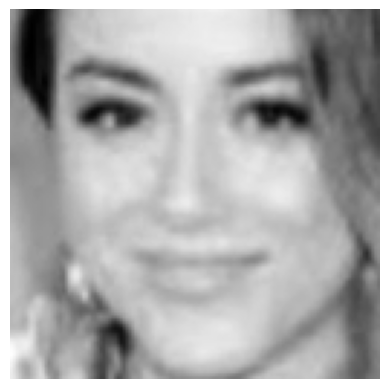

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(images[3].squeeze(), cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
#@title Label extracting

labels = [int(f.split('_')[0]) for f in filenames]
labels = torch.tensor(labels, dtype=torch.float32)
labels = torch.where(labels>80,80,labels)  #bỏ luôn mấy cái tuổi cao mà ít data
labels_nor = labels / labels.max()

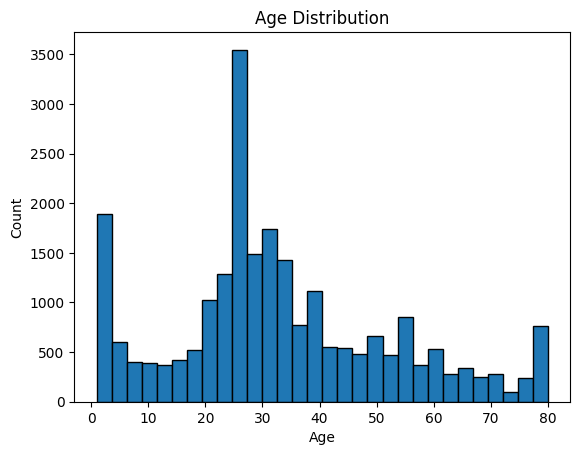

In [ ]:
import matplotlib.pyplot as plt

plt.hist(labels, bins=30, edgecolor='black')
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution")
plt.show()

In [ ]:
#@title Train - val split

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    images, labels_nor,
    test_size = 0.2,
    random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_val, y_val,
    test_size = 0.2,
    random_state=42
)



In [ ]:
y_train.shape,y_val.shape

(torch.Size([18966]), torch.Size([3793]))

In [ ]:
#@title Sampler - cái này con tham khảo AI, mục đích của code này là cân bằng lại dataset để không bias cái mode

from torch.utils.data import WeightedRandomSampler
import numpy as np


bins = np.linspace(y_train.min(), y_train.max(), 30)
bin_idx = np.digitize(y_train, bins)
bin_counts = np.bincount(bin_idx)
bin_counts[bin_counts == 0] = 1
sample_weights = 1.0 / bin_counts[bin_idx]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


#**DataLoader**


In [ ]:
from torch.utils.data import Dataset, DataLoader
class AgeDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels


    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx].float() / 255.0
        return img, self.labels[idx]

train_dataset = AgeDataset(X_train,y_train)
val_dataset = AgeDataset(X_val,y_val)

train_loader = DataLoader(train_dataset, batch_size=32,num_workers=2, pin_memory=True, sampler=sampler)
val_loader = DataLoader(val_dataset, batch_size=32,num_workers=2, pin_memory=True,shuffle=True)

#**Design and train**

In [ ]:
import torch.nn as nn
class Age_Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1,32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(64,128,kernel_size=3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128,256,kernel_size=3,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),


        )
        self.fc = nn.Sequential(
            nn.Flatten(),

            nn.Linear(256*8*8, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,1),
            nn.Sigmoid()
        )


    def forward(self,x):
        x = self.layers(x)
        x = self.fc(x)
        return x

image1, label1 = train_dataset[:2]
model_test = Age_Model()
model_test(image1).shape

torch.Size([2, 1])

In [ ]:
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_train = Age_Model()
model = model_train.to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

def train_model(model,epochs):
    history = {'Train loss':[],'Val loss':[]}
    for epoch in tqdm(range(epochs)):
        model.train()
        train_loss = 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            y_ = model(X)
            loss = criterion(y_.squeeze(1),y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * X.size(0)
        train_loss = train_loss / len(train_loader.dataset)
        history['Train loss'].append(train_loss)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                y_ = model(X)
                loss = criterion(y_.squeeze(1), y)
                val_loss += loss.item() * X.size(0)
        val_loss = val_loss / len(val_loader.dataset)
        history['Val loss'].append(val_loss)

    return history






In [ ]:
import plotly.graph_objects as go

history = train_model(model,30)
fig = go.Figure(data=[go.Scatter(y=history['Train loss'], name='Train'),
                      go.Scatter(y=history['Val loss'], name='Val')])
fig.show()

100%|██████████| 30/30 [08:32<00:00, 17.07s/it]


#**Evaluate**

In [ ]:

model.eval()

with torch.no_grad():
    test_img = X_val[:20].to(device)
    test_img = test_img.float() / 255
    y_pred = model(test_img).cpu() * labels.max()


torch.abs(torch.tensor(y_pred).squeeze() - y_val[:20]*labels.max())   #los


/tmp/ipykernel_674/1766702812.py:9: UserWarning:

To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).



tensor([ 0.1180,  1.0763, 11.0482,  5.0942,  9.4715,  2.2081,  2.8366,  6.5127,
         4.7654, 10.0399,  0.2507,  4.2693,  1.7562, 25.9852, 14.3357,  6.5983,
         0.6611,  1.9453,  0.4913,  0.6074])

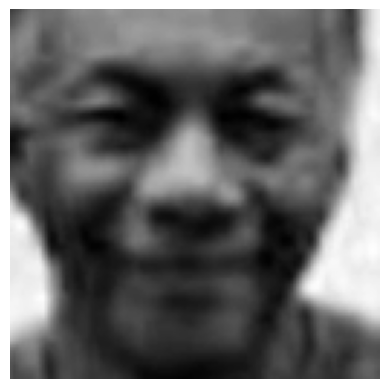

(None, tensor(72.), tensor([60.9518]))

In [ ]:
import matplotlib.pyplot as plt

def show_image(tensor_img):
    img = tensor_img.cpu().detach()
    img = img.permute(1, 2, 0)
    img = img.numpy()
    plt.imshow(img,cmap='gray')
    plt.axis('off')
    plt.show()


indexx = 2

show_image(X_val[indexx]), y_val[indexx]*labels.max(), y_pred[indexx]

torch.Size([5, 1])


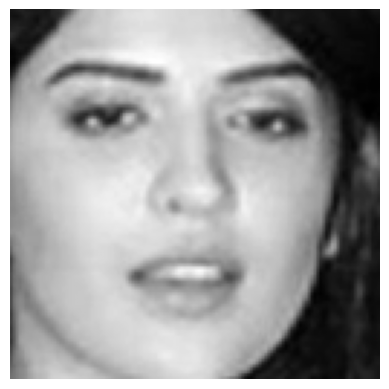

Pred:tensor([22.7168]), True:24.0


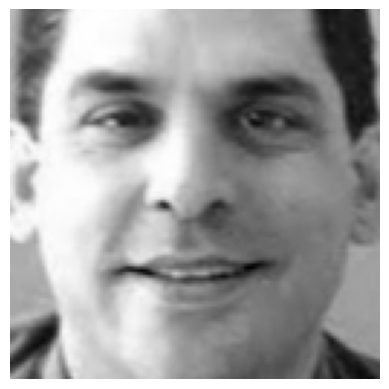

Pred:tensor([30.3348]), True:28.0


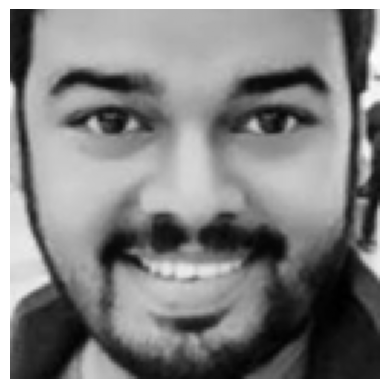

Pred:tensor([30.0189]), True:27.0


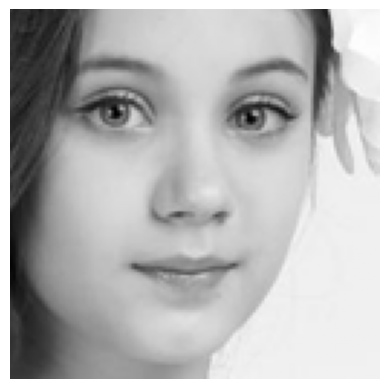

Pred:tensor([16.7876]), True:14.0


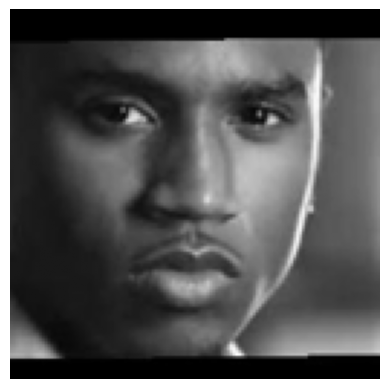

Pred:tensor([25.1621]), True:28.0


In [ ]:
model.eval()
with torch.no_grad():
    test_img = X_test[5:10].to(device)
    test_img = test_img.float() / 255
    y_pred = model(test_img).cpu() * 80
    y_true = y_test[5:10] * 80
    print(y_pred.shape)

for i in range(y_pred.shape[0]):
    show_image(test_img[i])
    print(f'Pred:{y_pred[i]}, True:{y_true[i]}')

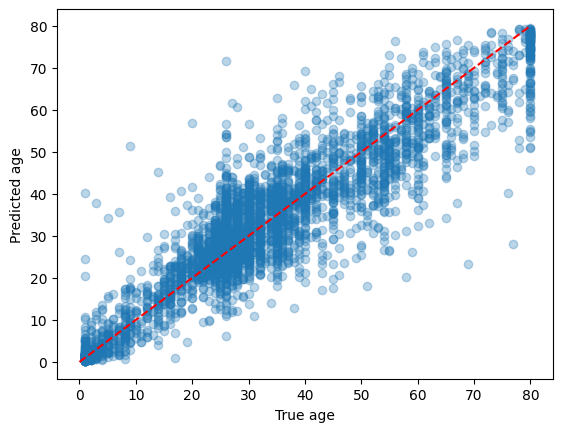

In [ ]:
model.eval()

with torch.no_grad():
    preds_all, true_all = [], []
    for X, y in val_loader:
        X = X.to(device)
        pred = model(X).squeeze(1).cpu().numpy()
        pred_age = pred * 80
        true_age = y.numpy().reshape(-1,1).flatten() * 80
        preds_all.extend(pred_age)
        true_all.extend(true_age)

import matplotlib.pyplot as plt
plt.scatter(true_all, preds_all, alpha=0.3)
plt.plot([0,80],[0,80],'r--')
plt.xlabel('True age')
plt.ylabel('Predicted age')
plt.show()

In [ ]:
torch.save(model.state_dict(), 'age_modelfinal3.pth')